In [1]:
import sys
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import importlib
from statsmodels.tsa.stattools import coint
from pathlib import Path

# --- 1. SETUP & RELOAD ---
warnings.filterwarnings('ignore')
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Force reload to ensure the Benchmark uses the 15bps fees and RFR logic
import src.backtester
importlib.reload(src.backtester)
from src.backtester import VectorizedBacktester

DATA_PROCESSED = project_root / "data_processed"
plt.style.use("bmh")

print(" STEP 1: Running Bulletproof Traditional Benchmark (Net-of-Costs)...")

def run_traditional_backtest(
    market_name,
    cohort_name,
    price_file
):

    print(f"\n{'='*60}")
    print(f"RUNNING TRADITIONAL: {market_name} ({cohort_name.upper()})")
    print("="*60)

    price_path = DATA_PROCESSED / price_file

    prices = pd.read_parquet(price_path)

    # -------------------------------------------------------
    # Backtester
    # -------------------------------------------------------

    m_key = "NIFTY" if "NIFTY" in market_name.upper() else "SPX"

    bt = VectorizedBacktester(
        prices,
        market=m_key,
        entry_z=2.0,
        stop_loss=-0.05,
        take_profit=0.15
    )

    # -------------------------------------------------------
    # Survivorship Filter
    # -------------------------------------------------------

    cutoff = (
        pd.Timestamp("2007-02-01")
        if cohort_name == "long"
        else pd.Timestamp("2015-02-01")
    )

    valid = []

    for col in prices.columns:

        first = prices[col].first_valid_index()

        if first is not None and first <= cutoff:
            valid.append(col)

    prices = prices[valid]

    print(f"Universe Size : {len(prices.columns)}")

    # -------------------------------------------------------
    # Correlation Filter
    # -------------------------------------------------------

    corr = prices.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    corr_pairs = corr.where(mask).stack()

    corr_pairs = corr_pairs[corr_pairs > 0.80]

    candidates = corr_pairs.sort_values(ascending=False)

    print(f"Correlation Candidates : {len(candidates)}")

    # -------------------------------------------------------
    # Cointegration
    # -------------------------------------------------------

    all_results = []

    tested = 0

    MAX_CANDIDATES = 250

    for i, ((s1, s2), corr_value) in enumerate(
        candidates.iloc[:MAX_CANDIDATES].items(),
        start=1
    ):

        if i % 100 == 0 or i == 1:
            print(f"Processing pair {i}/{MAX_CANDIDATES}")

        try:

            pair = pd.concat(
                [prices[s1], prices[s2]],
                axis=1
            ).dropna()

            if len(pair) < 252:
                continue

            _, pvalue, _ = coint(
                pair.iloc[:,0],
                pair.iloc[:,1]
            )

            if pvalue >= 0.05:
                continue

            result = bt.run_pair_backtest(
                s1,
                s2
            )

            if result:

                result["Correlation"] = corr_value
                result["Cointegration_P"] = pvalue

                all_results.append(result)

                tested += 1

        except:
            continue

    if len(all_results) == 0:

        print("No valid traditional pairs.")

        return None

    # -------------------------------------------------------
    # Results DataFrame
    # -------------------------------------------------------

    results_df = (
        pd.DataFrame(all_results)
        .sort_values("Sharpe", ascending=False)
        .reset_index(drop=True)
    )

    results_df["Rank"] = np.arange(1, len(results_df)+1)

    results_df["Total_Return"] = results_df["ROI"] * 100

    # -------------------------------------------------------
    # Summary
    # -------------------------------------------------------

    print("\nSUMMARY\n")

    summary = pd.DataFrame({

        "Metric":[

            "Pairs Backtested",

            "Average Sharpe",

            "Median Sharpe",

            "Best Sharpe",

            "Average CAGR",

            "Average Return",

            "Average Drawdown",

            "Winning Pairs"

        ],

        "Value":[

            len(results_df),

            results_df["Sharpe"].mean(),

            results_df["Sharpe"].median(),

            results_df["Sharpe"].max(),

            results_df["CAGR"].mean(),

            results_df["Total_Return"].mean(),

            results_df["Max_Drawdown"].mean(),

            (results_df["Total_Return"]>0).mean()*100

        ]

    })

    print(summary)

    # -------------------------------------------------------
    # Top 10
    # -------------------------------------------------------

    print("\nTOP 10 TRADITIONAL PAIRS\n")

    print(

        results_df[
            [
                "Rank",
                "ticker1",
                "ticker2",
                "Sharpe",
                "CAGR",
                "Total_Return",
                "Max_Drawdown"
            ]
        ].head(10)

    )

    # -------------------------------------------------------
    # Portfolio
    # -------------------------------------------------------

    pair_df = results_df[
        [
            "ticker1",
            "ticker2"
        ]
    ].rename(
        columns={
            "ticker1":"Ticker1",
            "ticker2":"Ticker2"
        }
    )

    portfolio = bt.portfolio_backtest(
        pair_df,
        weighting="equal"
    )

    if portfolio:

        print("\nPORTFOLIO\n")

        print(f"Sharpe      : {portfolio['Sharpe']:.2f}")
        print(f"CAGR        : {portfolio['CAGR']:.2f}%")
        print(f"ROI         : {portfolio['ROI']*100:.2f}%")
        print(f"Drawdown    : {portfolio['Max_Drawdown']:.2f}%")
        print(f"Sortino     : {portfolio['Sortino']:.2f}")
        print(f"Calmar      : {portfolio['Calmar']:.2f}")
        print(f"Trades      : {portfolio['Trade_Count']}")

    # -------------------------------------------------------
    # Save CSV
    # -------------------------------------------------------

    output = (
        f"traditional_{m_key.lower()}_{cohort_name}.csv"
    )

    results_df.to_csv(
        output,
        index=False
    )

    print(f"\nSaved : {output}")

    return results_df

# --- EXECUTION ---
res_n_long = run_traditional_backtest(
    "NIFTY 500",
    "long",
    "nifty500_prices.parquet"
)

res_n_broad = run_traditional_backtest(
    "NIFTY 500",
    "broad",
    "nifty500_2015_prices.parquet"
)

res_s_long = run_traditional_backtest(
    "S&P 500",
    "long",
    "sp500_prices.parquet"
)

res_s_broad = run_traditional_backtest(
    "S&P 500",
    "broad",
    "sp500_2015_prices.parquet"
)

 STEP 1: Running Bulletproof Traditional Benchmark (Net-of-Costs)...

RUNNING TRADITIONAL: NIFTY 500 (LONG)
Universe Size : 245
Correlation Candidates : 16347
Processing pair 1/250
Processing pair 100/250
Processing pair 200/250

SUMMARY

             Metric       Value
0  Pairs Backtested  199.000000
1    Average Sharpe   -0.763393
2     Median Sharpe   -0.807902
3       Best Sharpe    0.004386
4      Average CAGR   -9.696252
5    Average Return  -77.630833
6  Average Drawdown  -86.853882
7     Winning Pairs    1.507538

TOP 10 TRADITIONAL PAIRS

   Rank        ticker1        ticker2    Sharpe      CAGR  Total_Return  \
0     1        JBMA.NS     OLECTRA.NS  0.004386  2.120128     47.920596   
1     2  JBCHEPHARM.NS  LINDEINDIA.NS -0.092105  2.799334     67.399179   
2     3      HONAUT.NS         IGL.NS -0.137250  2.279576     52.290523   
3     4        JBMA.NS     RKFORGE.NS -0.224875 -3.831965    -51.768202   
4     5        FACT.NS        NTPC.NS -0.232306 -2.057673    -32.158212

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PROCESSED = Path.cwd().parent / "data_processed"

# Reload saved strict benchmark
df_benchmark = pd.read_csv(DATA_PROCESSED / "traditional_benchmark_strict.csv")

df_benchmark

,Market,Cohort,Ticker1,Ticker2,Sharpe,ROI,Max_Drawdown
0,NIFTY 500,long,ACE.NS,ELECON.NS,0.913021,485.345741,-31.596186
1,NIFTY 500,broad,ACE.NS,ELECON.NS,0.869044,26.412451,-31.216507
2,S&P 500,long,A,PLD,0.440279,6.960701,-36.147210
3,S&P 500,broad,ADI,DOV,0.423989,1.992714,-23.946506


In [3]:
"A" in sp_long_prices.columns, "PLD" in sp_long_prices.columns

NameError: name 'sp_long_prices' is not defined

In [ ]:
print(res_sp)

NameError: name 'res_sp' is not defined

In [ ]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
DATA_PROCESSED = project_root / "data_processed"

sp_long_prices = pd.read_parquet(DATA_PROCESSED / "sp500_prices.parquet")

In [ ]:
import sys
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.backtester import VectorizedBacktester

In [ ]:
bt_sp = VectorizedBacktester(
    sp_long_prices,
    market="SPX",
    entry_z=2.0,
    stop_loss=-0.05,
    take_profit=0.15
)

In [ ]:
res_sp = bt_sp.run_pair_backtest("A", "PLD")

In [ ]:
print(res_sp)

{'ticker1': 'A', 'ticker2': 'PLD', 'ROI': np.float64(6.96070144939876), 'CAGR': np.float64(11.592866245370082), 'Sharpe': np.float64(0.4402791712147242), 'Max_Drawdown': np.float64(-36.14720974915489), 'Trades': 436, 'equity_curve': Date
2007-01-31    1.000000
2007-02-01    1.000000
2007-02-02    1.000000
2007-02-05    1.000000
2007-02-06    1.000000
                ...   
2025-12-23    7.960701
2025-12-24    7.960701
2025-12-26    7.960701
2025-12-29    7.960701
2025-12-30    7.960701
Length: 4760, dtype: float64}


In [ ]:
equity_sp = res_sp["equity_curve"]
equity_sp.head()

Date
2007-01-31    1.0
2007-02-01    1.0
2007-02-02    1.0
2007-02-05    1.0
2007-02-06    1.0
dtype: float64

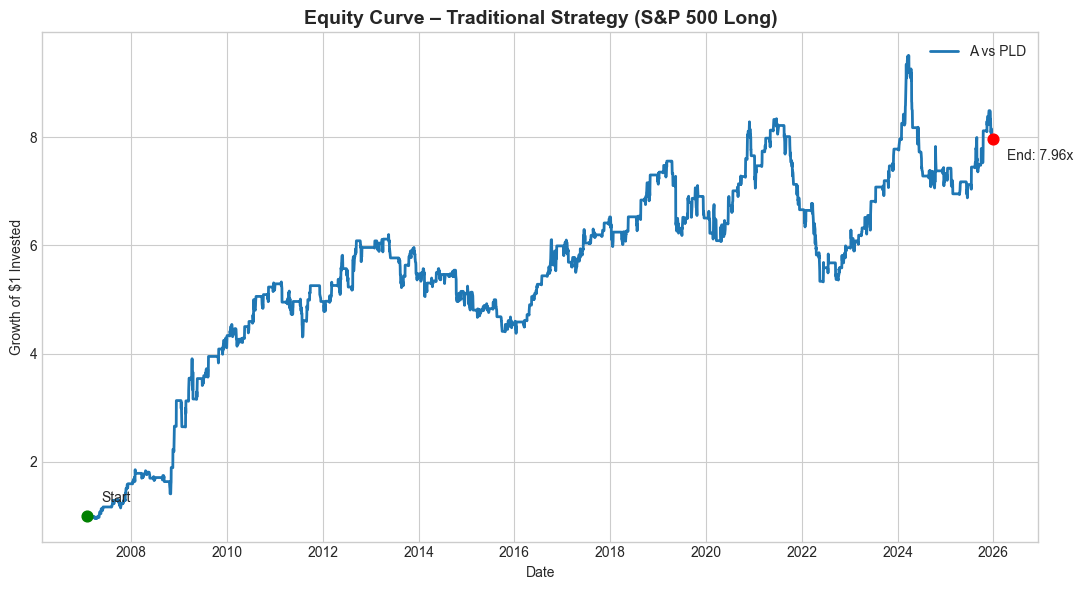

In [ ]:
fig, ax = plt.subplots(figsize=(11,6))

ax.plot(equity_sp.index,
        equity_sp.values,
        linewidth=2,
        label="A vs PLD")

# Mark start and end
ax.scatter(equity_sp.index[0], equity_sp.iloc[0], color="green", s=60, zorder=5)
ax.scatter(equity_sp.index[-1], equity_sp.iloc[-1], color="red", s=60, zorder=5)

ax.annotate("Start",
            (equity_sp.index[0], equity_sp.iloc[0]),
            textcoords="offset points", xytext=(10,10))

ax.annotate(f"End: {equity_sp.iloc[-1]:.2f}x",
            (equity_sp.index[-1], equity_sp.iloc[-1]),
            textcoords="offset points", xytext=(10,-15))

ax.set_title("Equity Curve – Traditional Strategy (S&P 500 Long)",
             fontsize=14, weight="bold")

ax.set_ylabel("Growth of $1 Invested")
ax.set_xlabel("Date")

ax.legend()

plt.tight_layout()
plt.savefig("figure_4_10_sp_traditional.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

DATA_PROCESSED = Path.cwd().parent / "data_processed"

nifty_long_prices = pd.read_parquet(DATA_PROCESSED / "nifty500_prices.parquet")

In [ ]:
from src.backtester import VectorizedBacktester

bt_nifty = VectorizedBacktester(
    nifty_long_prices,
    market="NIFTY",
    entry_z=2.0,
    stop_loss=-0.05,
    take_profit=0.15
)

In [ ]:
res_nifty = bt_nifty.run_pair_backtest("ACE.NS", "ELECON.NS")

print(res_nifty)

{'ticker1': 'ACE.NS', 'ticker2': 'ELECON.NS', 'ROI': np.float64(485.3457408658393), 'CAGR': np.float64(38.69734220523464), 'Sharpe': np.float64(0.9130206526964475), 'Max_Drawdown': np.float64(-31.596186077593906), 'Trades': 500, 'equity_curve': Date
2007-01-31      1.000000
2007-02-01      0.998045
2007-02-02      1.025912
2007-02-05      1.033378
2007-02-06      1.035340
                 ...    
2025-12-24    486.345741
2025-12-25    486.345741
2025-12-26    486.345741
2025-12-29    486.345741
2025-12-30    486.345741
Length: 4672, dtype: float64}


In [ ]:
equity_nifty = res_nifty["equity_curve"]

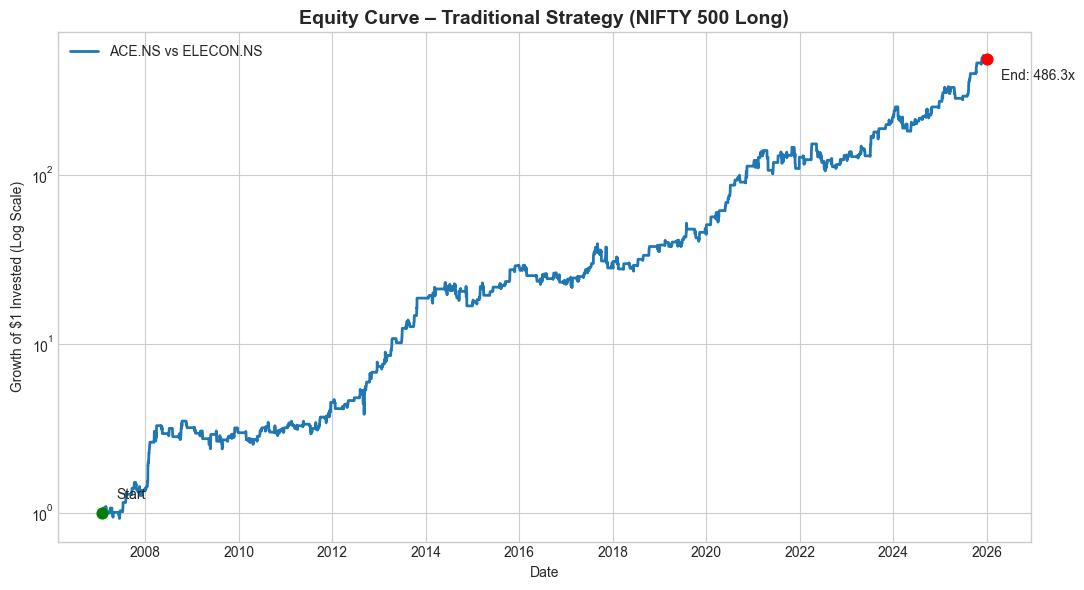

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(11,6))

# Log scale for readability
ax.plot(equity_nifty.index,
        equity_nifty.values,
        linewidth=2,
        label="ACE.NS vs ELECON.NS")

ax.set_yscale("log")

# Mark start and end points
ax.scatter(equity_nifty.index[0], equity_nifty.iloc[0], color="green", s=60, zorder=5)
ax.scatter(equity_nifty.index[-1], equity_nifty.iloc[-1], color="red", s=60, zorder=5)

ax.annotate("Start",
            (equity_nifty.index[0], equity_nifty.iloc[0]),
            textcoords="offset points", xytext=(10,10))

ax.annotate(f"End: {equity_nifty.iloc[-1]:.1f}x",
            (equity_nifty.index[-1], equity_nifty.iloc[-1]),
            textcoords="offset points", xytext=(10,-15))

ax.set_title("Equity Curve – Traditional Strategy (NIFTY 500 Long)",
             fontsize=14, weight="bold")

ax.set_ylabel("Growth of $1 Invested (Log Scale)")
ax.set_xlabel("Date")

ax.legend()

plt.tight_layout()
plt.savefig("figure_4_9_nifty_traditional.png", dpi=300, bbox_inches="tight")
plt.show()